In [53]:
#pip install imblearn

In [54]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.compose import ColumnTransformer
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [55]:
df=pd.read_csv("diabetes.csv")
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [56]:
df.info

<bound method DataFrame.info of        gender   age  hypertension  heart_disease smoking_history    bmi  \
0      Female  80.0             0              1           never  25.19   
1      Female  54.0             0              0         No Info  27.32   
2        Male  28.0             0              0           never  27.32   
3      Female  36.0             0              0         current  23.45   
4        Male  76.0             1              1         current  20.14   
...       ...   ...           ...            ...             ...    ...   
99995  Female  80.0             0              0         No Info  27.32   
99996  Female   2.0             0              0         No Info  17.37   
99997    Male  66.0             0              0          former  27.83   
99998  Female  24.0             0              0           never  35.42   
99999  Female  57.0             0              0         current  22.43   

       HbA1c_level  blood_glucose_level  diabetes  
0              

In [57]:
df.isnull().sum()/len(df)*100

gender                 0.0
age                    0.0
hypertension           0.0
heart_disease          0.0
smoking_history        0.0
bmi                    0.0
HbA1c_level            0.0
blood_glucose_level    0.0
diabetes               0.0
dtype: float64

In [58]:
df.shape

(100000, 9)

In [59]:
df.diabetes.value_counts()

diabetes
0    91500
1     8500
Name: count, dtype: int64

In [60]:
cat_col=df.select_dtypes("O").columns
cat_col

Index(['gender', 'smoking_history'], dtype='object')

In [61]:
num_col=df.select_dtypes(include=("int","float")).columns
num_col

Index(['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level',
       'blood_glucose_level', 'diabetes'],
      dtype='object')

In [71]:
num_col=['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level',
       'blood_glucose_level']
cat_col=['gender', 'smoking_history']

In [72]:
X=df.drop('diabetes',axis=1)
y=df['diabetes']

In [73]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(f'Size of traning data:{X_train.shape}')
print(f'Size of testing data:{X_test.shape}')

Size of traning data:(80000, 8)
Size of testing data:(20000, 8)


In [74]:
#Define separate piplines for numeric and categorical features
#StandardScalar for numeric features
numeric_transformer=Pipeline([
    ('scaler',StandardScaler())
])

#OneHotencoder for categorical features
#Specify which columns are numeric and categorical
categorical_transformer=Pipeline([
    ('encoder',OneHotEncoder())
])

#define a ColumnsTransformer to combine the Pipeline(same as before)
preprocessor=ColumnTransformer([
    ('numeric',numeric_transformer,num_col),
    ('categorical',categorical_transformer,cat_col)
])

In [75]:
#Create an SMOTE instance
#SMote can help alleviate class imblance issue 
smt=SMOTE(random_state=42)

In [76]:
#Create a fiinal pipeline with the preprocessor, SMOTE, and your chosen model(Random Forest)
final_pipeline=Pipeline([
    ('preprocessor',preprocessor),
    ('smote',smt),
    ('classifier',RandomForestClassifier())
])

In [77]:
final_pipeline

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [79]:
#fit the final pipeline on the training data
final_pipeline.fit(X_train,y_train)

#Evaluate the final pipeline on the test data (unseen data)
accuracy=final_pipeline.score(X_train,y_train)
y_pred=final_pipeline.predict(X_test)
print("Test Accuracy:", accuracy)

Test Accuracy: 0.9993125


In [80]:
class_report=classification_report(y_test,y_pred)
print("classification Report:\n", class_report)

classification Report:
               precision    recall  f1-score   support

           0       0.98      0.98      0.98     18292
           1       0.76      0.75      0.75      1708

    accuracy                           0.96     20000
   macro avg       0.87      0.86      0.87     20000
weighted avg       0.96      0.96      0.96     20000



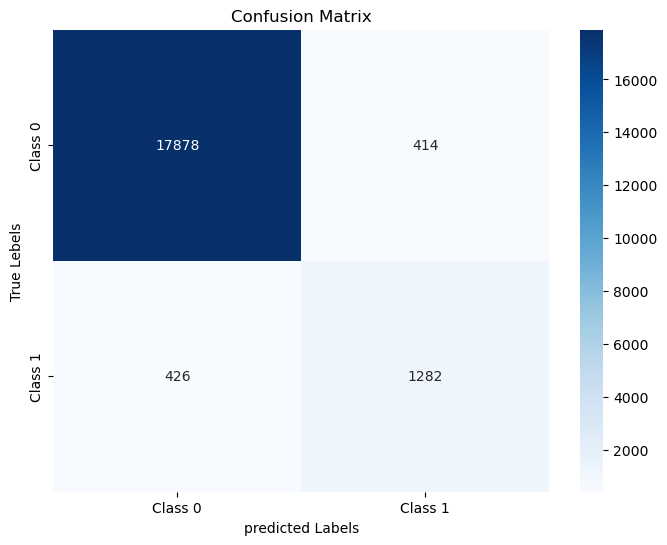

In [83]:
conf_matrix=confusion_matrix(y_test,y_pred)

#Create a heatmap using seaborn
plt.figure(figsize=(8,6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Class 0','Class 1'],yticklabels=['Class 0','Class 1'])
plt.xlabel('predicted Labels')
plt.ylabel('True Lebels')
plt.title('Confusion Matrix')
plt.show()


In [84]:
import pickle 
pickle.dump(final_pipeline,open("model.pkl","wb"))